In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor

df = pd.read_csv("../01 - DataPreparation/df_prepared.csv")

In [25]:
feature_cols = ['MinPlayers', 'MaxPlayers_log', 'Rating',
       'IsReimplementation', 'Kickstarted', 'Cat:Thematic', 'Cat:Strategy',
       'Cat:War', 'Cat:Family', 'Cat:CGS', 'Cat:Abstract', 'Cat:Party',
       'Cat:Childrens', 'Age', 'AgeRec', 'NumOwned_log', 'NumAlternates_log',
       'NumExpansions_log', 'NumImplementations_log', 'NumWant_log', 'AvgPlaytime_log']


In [26]:
X = df[feature_cols].copy()
y = df['GameWeight'].copy()

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [28]:
preprocess = ColumnTransformer(
    transformers=[("rating", OneHotEncoder(handle_unknown="ignore"), ["Rating"])],
    remainder="passthrough"
)

model = Pipeline(steps=[
    ("prep", preprocess),
    ("xgb", XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])


In [29]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Baseline:")
print(f"MAE:  {mean_absolute_error(y_test, y_pred):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.3f}")
print(f"R²:   {r2_score(y_test, y_pred):.3f}")

Baseline:
MAE:  0.309
RMSE: 0.409
R²:   0.736


Baseline XGBoost Regressor performs very well for predicting GameWeight: MAE = 0.309, RMSE = 0.409, and R² = 0.736, meaning it explains about 74% of the variance with relatively low average error.

In [30]:
param_grid = {
    "xgb__n_estimators": [300, 600],
    "xgb__learning_rate": [0.05, 0.1],
    "xgb__max_depth": [3, 5],
    "xgb__subsample": [0.8, 1.0],
    "xgb__colsample_bytree": [0.8, 1.0],
    "xgb__min_child_weight": [1, 5],
    "xgb__reg_alpha": [0.0, 0.01],
    "xgb__reg_lambda": [1.0, 5.0],
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    model,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1
)

grid.fit(X_train, y_train)
best_model = grid.best_estimator_

print("\nBest params:", grid.best_params_)
print("Best CV MAE:", round(-grid.best_score_, 3))


Best params: {'xgb__colsample_bytree': 0.8, 'xgb__learning_rate': 0.05, 'xgb__max_depth': 5, 'xgb__min_child_weight': 5, 'xgb__n_estimators': 600, 'xgb__reg_alpha': 0.0, 'xgb__reg_lambda': 5.0, 'xgb__subsample': 0.8}
Best CV MAE: 0.298


Tuned XGBoost Regressor uses a lower learning rate (0.05) with more trees (600) plus subsampling/colsampling (0.8) and stronger L2 regularization (reg_lambda=5.0) to improve generalization. This setup reduces error to a best CV MAE of 0.298, a small but clear improvement over the baseline.

In [31]:
y_pred = best_model.predict(X_test)

train_mae = mean_absolute_error(y_train, best_model.predict(X_train))
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\nTrain MAE:", round(train_mae, 3))
print(f"Test MAE:  {mae:.3f}")
print(f"Test RMSE: {rmse:.3f}")
print(f"Test R²:   {r2:.3f}")
print("Gap (test-train):", round(mae - train_mae, 3))


Train MAE: 0.247
Test MAE:  0.298
Test RMSE: 0.397
Test R²:   0.751
Gap (test-train): 0.051


The tuned XGBoost regressor achieves strong test performance (MAE = 0.298, RMSE = 0.397, R² = 0.751), improving slightly over the baseline. The train MAE (0.247) vs test MAE (0.298) shows some overfitting (gap 0.051), but overall generalization remains good.

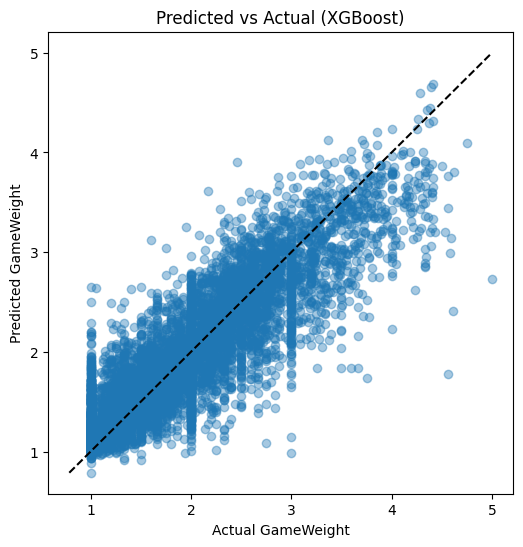

In [32]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.4)
mn = min(y_test.min(), y_pred.min())
mx = max(y_test.max(), y_pred.max())
plt.plot([mn, mx], [mn, mx], "k--")
plt.xlabel("Actual GameWeight")
plt.ylabel("Predicted GameWeight")
plt.title("Predicted vs Actual (XGBoost)")
plt.show()


The Predicted vs Actual (XGBoost) plot shows a tight alignment along the diagonal, indicating strong predictive accuracy overall. There’s still some regression-to-the-mean behavior: very high GameWeight values are slightly underpredicted and very low values slightly overpredicted, with moderate scatter and a few outliers.

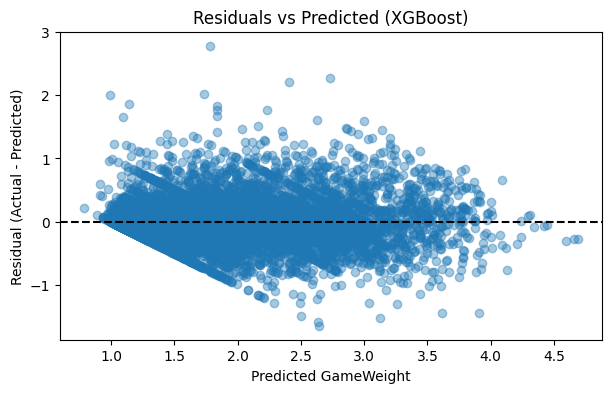

In [33]:
residuals = y_test - y_pred
plt.figure(figsize=(7,4))
plt.scatter(y_pred, residuals, alpha=0.4)
plt.axhline(0, linestyle="--", color="k")
plt.xlabel("Predicted GameWeight")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residuals vs Predicted (XGBoost)")
plt.show()

The residuals are mostly centered around 0, indicating low overall bias, but there’s a slight downward trend: the model tends to underpredict at low predicted GameWeight (positive residuals) and overpredict at higher predicted values (negative residuals). The spread is moderate with a few outliers.

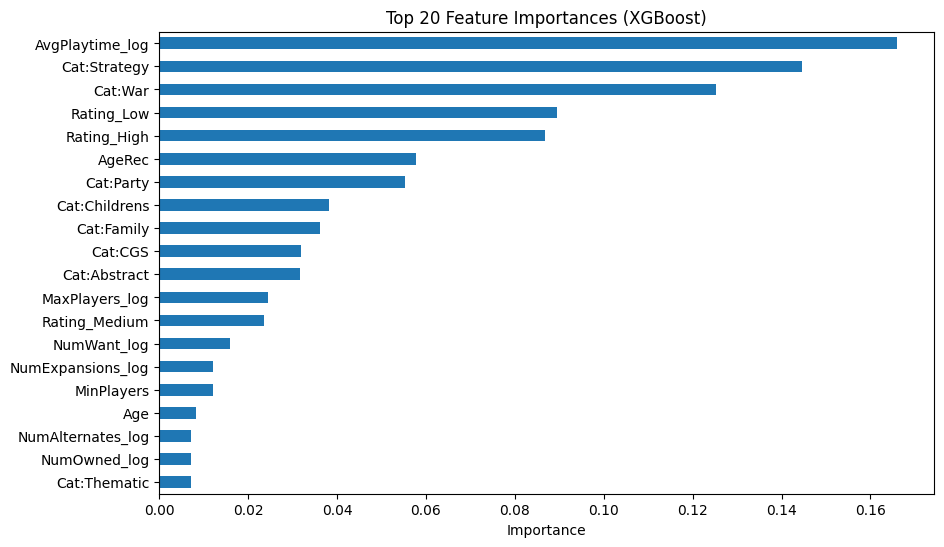

In [34]:
xgb = best_model.named_steps["xgb"]
prep = best_model.named_steps["prep"]

ohe = prep.named_transformers_["rating"]
rating_names = ohe.get_feature_names_out(["Rating"])
all_feature_names = list(rating_names) + [c for c in feature_cols if c != "Rating"]

importances = pd.Series(xgb.feature_importances_, index=all_feature_names).sort_values()

plt.figure(figsize=(10,6))
importances.tail(20).plot(kind="barh")
plt.title("Top 20 Feature Importances (XGBoost)")
plt.xlabel("Importance")
plt.show()

XGBoost relies most on AvgPlaytime_log as the strongest driver of GameWeight, followed by category signals (especially Strategy and War) and rating level indicators (Rating_Low/High). AgeRec has a moderate contribution, while the remaining features (players, ownership/want counts, expansions, other categories) add smaller incremental value.

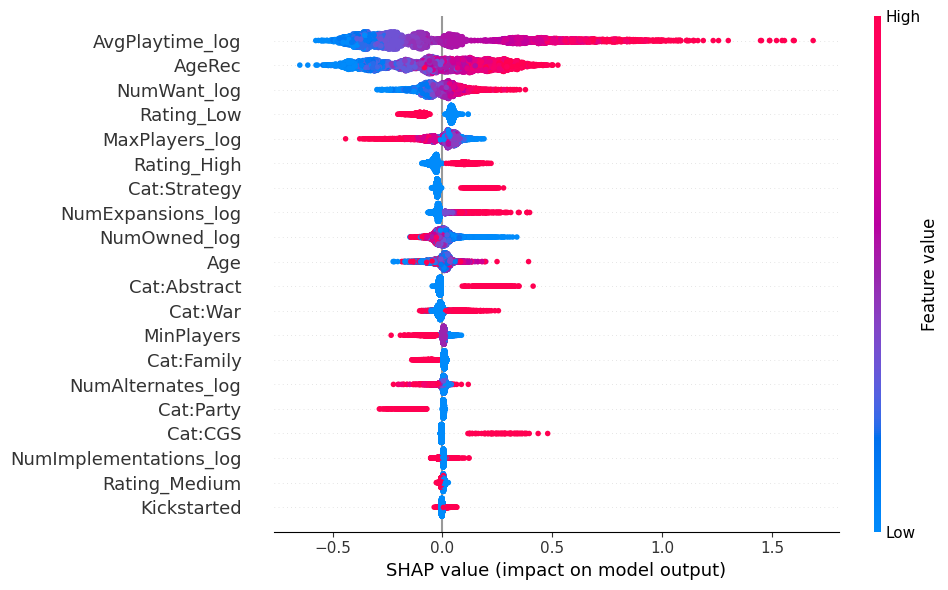

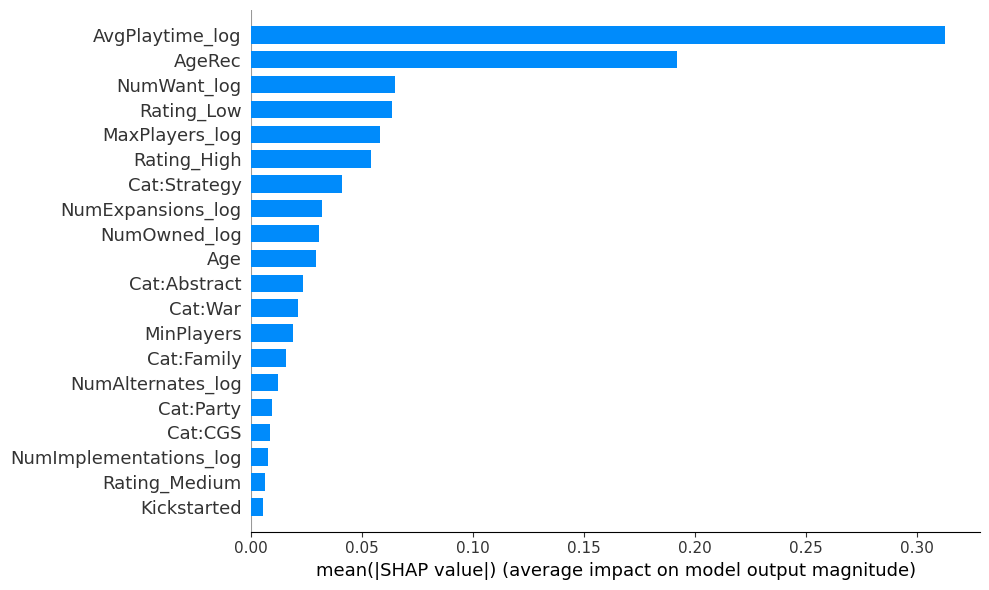

In [44]:
import shap
import numpy as np
import pandas as pd

prep = best_model.named_steps["prep"]
xgb  = best_model.named_steps["xgb"]

ohe = prep.named_transformers_["rating"]
rating_names = ohe.get_feature_names_out(["Rating"])
other_names = [c for c in feature_cols if c != "Rating"]
feature_names = list(rating_names) + other_names

X_test_prep = prep.transform(X_test)

X_shap = X_test_prep

explainer = shap.TreeExplainer(xgb)
shap_values = explainer(X_shap)


shap.summary_plot(shap_values, X_shap, feature_names=feature_names, plot_size=(10, 6))
shap.summary_plot(shap_values, X_shap, feature_names=feature_names, plot_type="bar", plot_size=(10, 6))


SHAP summary plots (XGBoost regressor) explain why the model predicts a certain GameWeight by showing how each feature contributes to pushing predictions up or down.

In the beeswarm graph each dot is a game. The X-axis (SHAP value) represents how much that feature changes the prediction (right = increases GameWeight, left = decreases). The color indicates the feature value.
What we get from it is that AvgPlaytime_log has the strongest impact—high playtime (red) generally pushes predictions higher; low playtime (blue) pushes them lower.


On the bottom plot we rank features by their average impact size as mean of abs(SHAP).


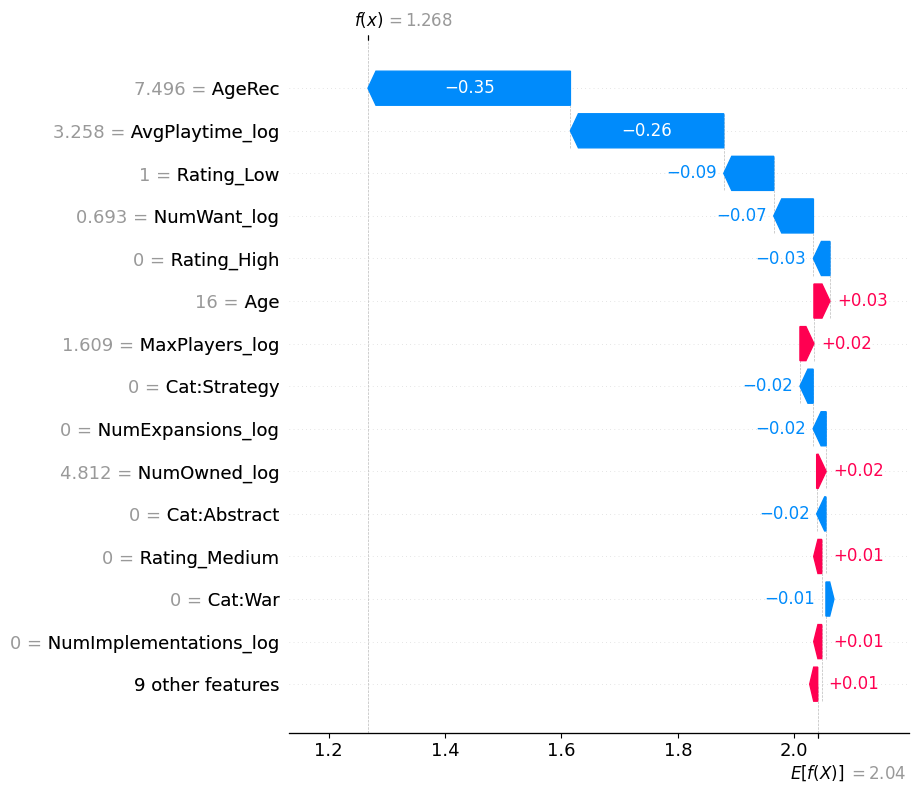

In [40]:
import shap
import pandas as pd
import re

prep = best_model.named_steps["prep"]
xgb  = best_model.named_steps["xgb"]

feature_names = prep.get_feature_names_out()
feature_names = [re.sub(r'^(rating|remainder)__', '', f) for f in feature_names]


X_test_prep = prep.transform(X_test)
X_test_prep_df = pd.DataFrame(X_test_prep, columns=feature_names)


explainer = shap.TreeExplainer(xgb)
shap_values = explainer(X_test_prep_df)

i = 0
shap.plots.waterfall(shap_values[i], max_display=15)


This SHAP waterfall plot explains a single XGBoost prediction by showing how each feature moves the output from the baseline to the final prediction.


Baseline (E[f(X)]) ≈ 2.04: the model’s average predicted GameWeight across the dataset.
Final prediction (f(x)) = 1.268: the predicted GameWeight for this specific game.

Bars = feature contributions:
- Blue bars decrease the prediction
- Red bars increase the prediction

The values (e.g., -0.35) are the size of the shift caused by that feature.

For this example, the prediction is pushed down strongly mainly by AgeRec (-0.35) and AvgPlaytime_log (-0.26), with additional smaller decreases from Rating_Low, NumWant_log, and others. A few features (e.g., Age, MaxPlayers_log) slightly push the prediction up, but not enough to offset the larger negative contributions.